# N-body Implementation Comparison

Comparing loop-based (Numba) vs vectorized (NumPy) gravitational force calculations for a 5-year solar system simulation.


In [10]:
# Add project root to Python path
import sys
import os
sys.path.append(os.path.join(os.getcwd(), '..'))

import time
import numpy as np
from simulation.runner import run_simulation
from utils.plot_tools import plot_orbits_3d

# Simulation parameters
T = 10 * 365.25 * 24 * 3600  # 5 years
steps = 100

print(f"Simulating {T / (365.25 * 24 * 3600):.0f} years with {steps} time steps")


Simulating 10 years with 100 time steps


In [11]:
# Test loop-based implementation (Numba)
print("Running loop-based implementation (Numba + nested loops)...")
start_time = time.perf_counter()
bodies_loop, solution_loop = run_simulation(T, steps, file='ipynb', use_vectorized=False)
loop_time = time.perf_counter() - start_time
print(f"Loop-based execution time: {loop_time:.2f} seconds")

# Test vectorized implementation (NumPy)
print("\nRunning vectorized implementation (NumPy broadcasting)...")
start_time = time.perf_counter()
bodies_vec, solution_vec = run_simulation(T, steps, file='ipynb', use_vectorized=True)
vec_time = time.perf_counter() - start_time
print(f"Vectorized execution time: {vec_time:.2f} seconds")

print(f"\nPerformance comparison:")
print(f"Speedup ratio: {loop_time / vec_time:.1f}x")
print(f"Vectorized is {'faster' if vec_time < loop_time else 'slower'}")


Running loop-based implementation (Numba + nested loops)...
Loop-based execution time: 0.25 seconds

Running vectorized implementation (NumPy broadcasting)...
Vectorized execution time: 0.28 seconds

Performance comparison:
Speedup ratio: 0.9x
Vectorized is slower


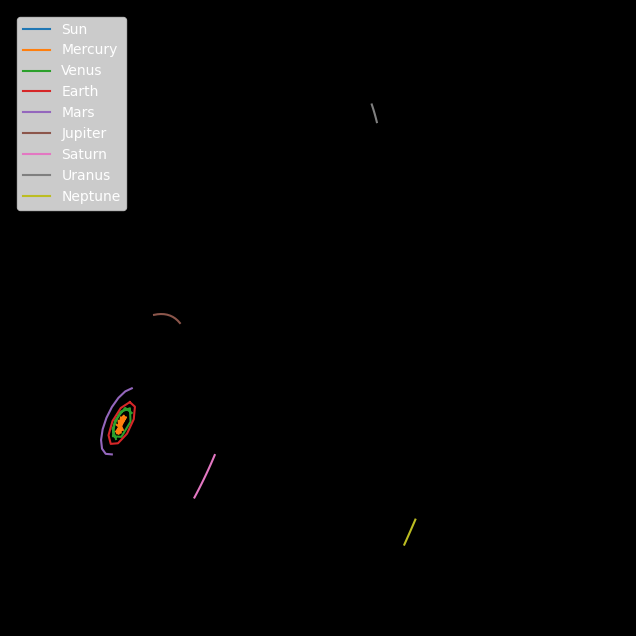

In [3]:
# Visualize orbital trajectories
plot_orbits_3d(bodies_vec)